In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [81]:
try:
    fear_greed = pd.read_csv(r"C:\Users\indur\Downloads\fear_greed_index.csv")
    print(fear_greed.to_string())
except:
    print("please check the path")
finally:
    print('we load successfully load fear_greed')

       timestamp  value classification        date
0     1517463000     30           Fear  2018-02-01
1     1517549400     15   Extreme Fear  2018-02-02
2     1517635800     40           Fear  2018-02-03
3     1517722200     24   Extreme Fear  2018-02-04
4     1517808600     11   Extreme Fear  2018-02-05
5     1517895000      8   Extreme Fear  2018-02-06
6     1517981400     36           Fear  2018-02-07
7     1518067800     30           Fear  2018-02-08
8     1518154200     44           Fear  2018-02-09
9     1518240600     54        Neutral  2018-02-10
10    1518327000     31           Fear  2018-02-11
11    1518413400     42           Fear  2018-02-12
12    1518499800     35           Fear  2018-02-13
13    1518586200     55          Greed  2018-02-14
14    1518672600     71          Greed  2018-02-15
15    1518759000     67          Greed  2018-02-16
16    1518845400     74          Greed  2018-02-17
17    1518931800     63          Greed  2018-02-18
18    1519018200     67        

In [82]:
try:
    historical = pd.read_csv(r"c:\Users\indur\Downloads\historical_data.csv")
    print(historical.to_string())
except:
    print("please check the path")
finally:
    print('we load successfully load fear_greed')

                                           Account       Coin  Execution Price   Size Tokens    Size USD  Side     Timestamp IST  Start Position                  Direction     Closed PnL                                                    Transaction Hash     Order ID  Crossed           Fee      Trade ID     Timestamp
0       0xae5eacaf9c6b9111fd53034a602c192a04e082ed       @107         7.976900  9.868700e+02     7872.16   BUY  02-12-2024 22:50    0.000000e+00                        Buy       0.000000  0xec09451986a1874e3a980418412fcd0201f500c95bac0f37caef8a734502ec49  52017706630     True  3.454045e-01  8.950000e+14  1.730000e+12
1       0xae5eacaf9c6b9111fd53034a602c192a04e082ed       @107         7.980000  1.600000e+01      127.68   BUY  02-12-2024 22:50    9.865246e+02                        Buy       0.000000  0xec09451986a1874e3a980418412fcd0201f500c95bac0f37caef8a734502ec49  52017706630     True  5.600000e-03  4.430000e+14  1.730000e+12
2       0xae5eacaf9c6b9111fd53034a602c192a0

In [83]:
# ---------------------------------------Part-A Data Preparation--------------------

In [84]:
print('Fear & Greed data_set before the cleaning')

print("Shap:",fear_greed.shape)
print("columns:",fear_greed.columns)
print("Missing Values:",fear_greed.isna().sum())
print("describe:",fear_greed.describe())
print("info:",fear_greed.info())
print("Duplicate rows :",fear_greed.duplicated().sum())
print("Drop duplicates:",fear_greed.drop_duplicates())


Fear & Greed data_set before the cleaning
Shap: (2644, 4)
columns: Index(['timestamp', 'value', 'classification', 'date'], dtype='object')
Missing Values: timestamp         0
value             0
classification    0
date              0
dtype: int64
describe:           timestamp        value
count  2.644000e+03  2644.000000
mean   1.631899e+09    46.981089
std    6.597967e+07    21.827680
min    1.517463e+09     5.000000
25%    1.574811e+09    28.000000
50%    1.631900e+09    46.000000
75%    1.688989e+09    66.000000
max    1.746164e+09    95.000000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2644 entries, 0 to 2643
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   timestamp       2644 non-null   int64 
 1   value           2644 non-null   int64 
 2   classification  2644 non-null   object
 3   date            2644 non-null   object
dtypes: int64(2), object(2)
memory usage: 82.8+ KB
info: None
Duplicate row

In [85]:
print('historical_data_set about before the cleaning ')

print("Shap:",historical.shape)
print("columns:",historical.columns)
print("describe:",historical.describe())
print("Missing Values:",historical.isna().sum())
print("info:",historical.info())
print("Duplicate rows :",historical.duplicated().sum())
print("Drop duplicates:",historical.drop_duplicates())

historical_data_set about before the cleaning 
Shap: (211224, 16)
columns: Index(['Account', 'Coin', 'Execution Price', 'Size Tokens', 'Size USD', 'Side',
       'Timestamp IST', 'Start Position', 'Direction', 'Closed PnL',
       'Transaction Hash', 'Order ID', 'Crossed', 'Fee', 'Trade ID',
       'Timestamp'],
      dtype='object')
describe:        Execution Price   Size Tokens      Size USD  Start Position  \
count    211224.000000  2.112240e+05  2.112240e+05    2.112240e+05   
mean      11414.723350  4.623365e+03  5.639451e+03   -2.994625e+04   
std       29447.654868  1.042729e+05  3.657514e+04    6.738074e+05   
min           0.000005  8.740000e-07  0.000000e+00   -1.433463e+07   
25%           4.854700  2.940000e+00  1.937900e+02   -3.762311e+02   
50%          18.280000  3.200000e+01  5.970450e+02    8.472793e+01   
75%         101.580000  1.879025e+02  2.058960e+03    9.337278e+03   
max      109004.000000  1.582244e+07  3.921431e+06    3.050948e+07   

          Closed PnL   

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211224 entries, 0 to 211223
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Account           211224 non-null  object 
 1   Coin              211224 non-null  object 
 2   Execution Price   211224 non-null  float64
 3   Size Tokens       211224 non-null  float64
 4   Size USD          211224 non-null  float64
 5   Side              211224 non-null  object 
 6   Timestamp IST     211224 non-null  object 
 7   Start Position    211224 non-null  float64
 8   Direction         211224 non-null  object 
 9   Closed PnL        211224 non-null  float64
 10  Transaction Hash  211224 non-null  object 
 11  Order ID          211224 non-null  int64  
 12  Crossed           211224 non-null  bool   
 13  Fee               211224 non-null  float64
 14  Trade ID          211224 non-null  float64
 15  Timestamp         211224 non-null  float64
dtypes: bool(1), float64(

In [86]:
#convert timestamps and align data set

In [87]:
# Convert date columns

fear_greed['date'] = pd.to_datetime(fear_greed['date']).dt.date
print(fear_greed.to_string())

       timestamp  value classification        date
0     1517463000     30           Fear  2018-02-01
1     1517549400     15   Extreme Fear  2018-02-02
2     1517635800     40           Fear  2018-02-03
3     1517722200     24   Extreme Fear  2018-02-04
4     1517808600     11   Extreme Fear  2018-02-05
5     1517895000      8   Extreme Fear  2018-02-06
6     1517981400     36           Fear  2018-02-07
7     1518067800     30           Fear  2018-02-08
8     1518154200     44           Fear  2018-02-09
9     1518240600     54        Neutral  2018-02-10
10    1518327000     31           Fear  2018-02-11
11    1518413400     42           Fear  2018-02-12
12    1518499800     35           Fear  2018-02-13
13    1518586200     55          Greed  2018-02-14
14    1518672600     71          Greed  2018-02-15
15    1518759000     67          Greed  2018-02-16
16    1518845400     74          Greed  2018-02-17
17    1518931800     63          Greed  2018-02-18
18    1519018200     67        

In [102]:
historical['Timestamp IST'] = pd.to_datetime(historical['Timestamp IST'],dayfirst=True)

historical['date'] = historical['Timestamp IST'].dt.date

print(historical)

                                           Account      Coin  Execution Price  \
0       0xae5eacaf9c6b9111fd53034a602c192a04e082ed      @107           7.9769   
1       0xae5eacaf9c6b9111fd53034a602c192a04e082ed      @107           7.9800   
2       0xae5eacaf9c6b9111fd53034a602c192a04e082ed      @107           7.9855   
3       0xae5eacaf9c6b9111fd53034a602c192a04e082ed      @107           7.9874   
4       0xae5eacaf9c6b9111fd53034a602c192a04e082ed      @107           7.9894   
...                                            ...       ...              ...   
211219  0x72743ae2822edd658c0c50608fd7c5c501b2afbd  FARTCOIN           1.1010   
211220  0x72743ae2822edd658c0c50608fd7c5c501b2afbd  FARTCOIN           1.1010   
211221  0x72743ae2822edd658c0c50608fd7c5c501b2afbd  FARTCOIN           1.1010   
211222  0x72743ae2822edd658c0c50608fd7c5c501b2afbd  FARTCOIN           1.1010   
211223  0x72743ae2822edd658c0c50608fd7c5c501b2afbd  FARTCOIN           1.1010   

        Size Tokens  Size U

In [89]:
# create key metrics

In [103]:
daily_pnl = historical.groupby(['Account','date'])['Closed PnL'].sum().reset_index()
daily_pnl.rename(columns={'Closed PnL':'daily_pnl'}, inplace=True)

print(daily_pnl)

                                         Account        date     daily_pnl
0     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-11      0.000000
1     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-17      0.000000
2     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-18      0.000000
3     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-22 -21227.000000
4     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-26   1603.100000
...                                          ...         ...           ...
2336  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-04-27   1709.194807
2337  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-04-28   4008.588908
2338  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-04-29   8561.771838
2339  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-04-30   2520.773814
2340  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-05-01   1364.022527

[2341 rows x 3 columns]


In [91]:

historical['win'] = np.where(historical['Closed PnL'] > 0, 1, 0)

win_rate = historical.groupby(['Account','date'])['win'].mean().reset_index()
win_rate.rename(columns={'win':'win_rate'}, inplace=True)

print("Sample Win Rate:")
print(win_rate.head())

Sample Win Rate:
                                      Account        date  win_rate
0  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-11  0.000000
1  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-17  0.000000
2  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-18  0.000000
3  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-22  0.000000
4  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-26  0.444444


In [92]:
trade_count = historical.groupby(['Account','date'])['Side'].count().reset_index()
trade_count.rename(columns={'Side':'trade_count'}, inplace=True)
print(trade_count)

                                         Account        date  trade_count
0     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-11          177
1     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-17           68
2     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-18           40
3     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-22           12
4     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-26           27
...                                          ...         ...          ...
2336  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-04-27           82
2337  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-04-28          430
2338  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-04-29          902
2339  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-04-30           75
2340  0xbee1707d6b44d4d52bfe19e41f8a828645437aab  2025-05-01          131

[2341 rows x 3 columns]


In [93]:
avg_trade_size = historical.groupby(['Account','date'])['Size USD'].mean().reset_index()
avg_trade_size.rename(columns={'Size USD':'avg_trade_size'}, inplace=True)

print("Sample Avg Trade Size:")
print(avg_trade_size.head())

Sample Avg Trade Size:
                                      Account        date  avg_trade_size
0  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-11     5089.718249
1  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-17     7976.664412
2  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-18    23734.500000
3  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-22    28186.666667
4  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-26    17248.148148


In [94]:
# Long - Short Ratio

long_short = historical.groupby(['Account','date','Side']).size().unstack(fill_value=0)

# Check actual Side values first
print("Unique Side values:", historical['Side'].unique())

# Ensure both BUY and SELL exist
if 'BUY' not in long_short.columns:
    long_short['BUY'] = 0
if 'SELL' not in long_short.columns:
    long_short['SELL'] = 0

long_short['long_short_ratio'] = long_short['BUY'] / (long_short['SELL'] + 1)

long_short = long_short.reset_index()[['Account','date','long_short_ratio']]

print(long_short.head())

Unique Side values: ['BUY' 'SELL']
Side                                     Account        date  long_short_ratio
0     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-11              0.00
1     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-17              0.00
2     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-18              0.00
3     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-22             12.00
4     0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-26              0.75


In [ ]:
# Merge All Daily Metrics

daily_metrics = daily_pnl.copy()

daily_metrics = pd.merge(daily_metrics,  win_rate,on=['Account','date'], how='left')

daily_metrics = pd.merge(daily_metrics, avg_trade_size,on=['Account','date'],how='left')

daily_metrics = pd.merge(daily_metrics, trade_count, on=['Account','date'],  how='left')

daily_metrics = pd.merge(daily_metrics, long_short,on=['Account','date'],  how='left')

print("Final Daily Metrics Shape:", daily_metrics.shape)
print(daily_metrics.head())

Final Daily Metrics Shape: (2341, 7)
                                      Account        date  daily_pnl  \
0  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-11        0.0   
1  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-17        0.0   
2  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-18        0.0   
3  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-22   -21227.0   
4  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-26     1603.1   

   win_rate  avg_trade_size  trade_count  long_short_ratio  
0  0.000000     5089.718249          177              0.00  
1  0.000000     7976.664412           68              0.00  
2  0.000000    23734.500000           40              0.00  
3  0.000000    28186.666667           12             12.00  
4  0.444444    17248.148148           27              0.75  


In [ ]:
# Merge with sentiment

merged = pd.merge( daily_metrics,fear_greed[['date','classification']],on='date', how='left')

print("Missing sentiment after merge:",merged['classification'].isnull().sum())

# Drop rows without sentiment
merged = merged.dropna(subset=['classification'])

print("Final merged dataset shape:", merged.shape)
print(merged.head())

Missing sentiment after merge: 1
Final merged dataset shape: (2340, 8)
                                      Account        date  daily_pnl  \
0  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-11        0.0   
1  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-17        0.0   
2  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-18        0.0   
3  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-22   -21227.0   
4  0x083384f897ee0f19899168e3b1bec365f52a9012  2024-11-26     1603.1   

   win_rate  avg_trade_size  trade_count  long_short_ratio classification  
0  0.000000     5089.718249          177              0.00  Extreme Greed  
1  0.000000     7976.664412           68              0.00  Extreme Greed  
2  0.000000    23734.500000           40              0.00  Extreme Greed  
3  0.000000    28186.666667           12             12.00  Extreme Greed  
4  0.444444    17248.148148           27              0.75  Extreme Greed  


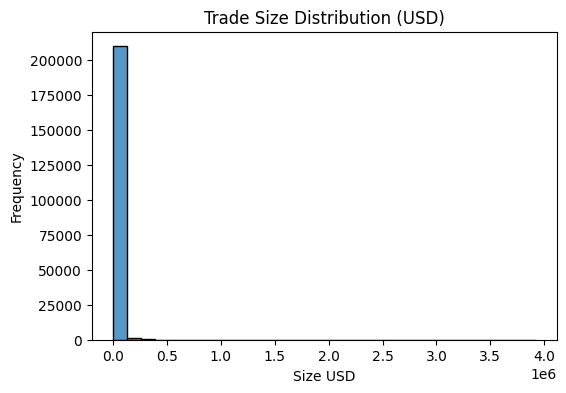

In [101]:
# Trade Size Distribution

plt.figure(figsize=(6,4))
sns.histplot(historical['Size USD'], bins=30)
plt.title("Trade Size Distribution (USD)")
plt.xlabel("Size USD")
plt.ylabel("Frequency")
plt.show()

In [104]:
#--------------------------------------------------------part B-------------------------------------------------------------
# Performance comparison

performance = merged.groupby('classification').agg({
    'daily_pnl': ['mean', 'std'],
    'win_rate': 'mean',
    'trade_count': 'mean',
    'avg_trade_size': 'mean'
}).reset_index()

print("Performance Summary:")
print(performance)

Performance Summary:
  classification    daily_pnl                win_rate trade_count  \
                         mean           std      mean        mean   
0   Extreme Fear  4619.439053  29534.839183  0.329659  133.750000   
1  Extreme Greed  5161.922644  27496.863832  0.386387   76.030418   
2           Fear  5328.818161  31659.771538  0.364033   98.153968   
3          Greed  3318.100730  30599.040173  0.343559   77.628086   
4        Neutral  3438.618818  17447.863645  0.355414  100.228723   

  avg_trade_size  
            mean  
0    6773.464125  
1    5371.637182  
2    8975.928546  
3    6427.866594  
4    6963.694861  


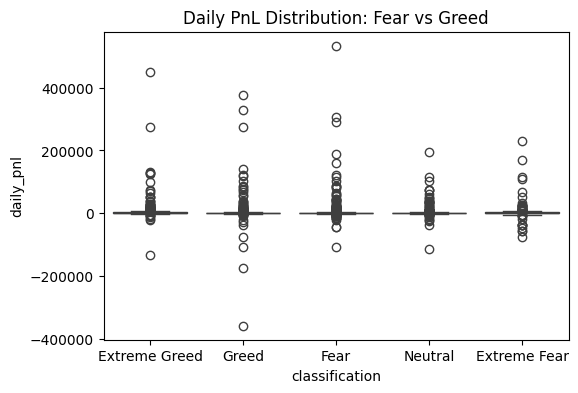

In [105]:
plt.figure(figsize=(6,4))
sns.boxplot(x='classification', y='daily_pnl', data=merged)
plt.title("Daily PnL Distribution: Fear vs Greed")
plt.show()

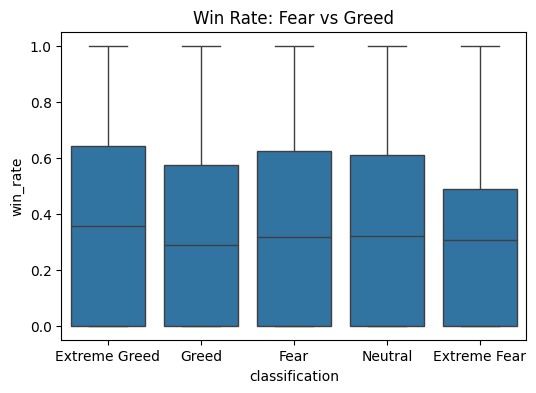

In [106]:
plt.figure(figsize=(6,4))
sns.boxplot(x='classification', y='win_rate', data=merged)
plt.title("Win Rate: Fear vs Greed")
plt.show()

In [107]:
volatility = merged.groupby('classification')['daily_pnl'].std()

print("PnL Volatility (Drawdown Proxy):")
print(volatility)

PnL Volatility (Drawdown Proxy):
classification
Extreme Fear     29534.839183
Extreme Greed    27496.863832
Fear             31659.771538
Greed            30599.040173
Neutral          17447.863645
Name: daily_pnl, dtype: float64


In [108]:
behavior = merged.groupby('classification').agg({
    'trade_count': 'mean',
    'avg_trade_size': 'mean',
    'long_short_ratio': 'mean'
}).reset_index()

print("Behavior Summary:")
print(behavior)

Behavior Summary:
  classification  trade_count  avg_trade_size  long_short_ratio
0   Extreme Fear   133.750000     6773.464125         12.261575
1  Extreme Greed    76.030418     5371.637182          5.430688
2           Fear    98.153968     8975.928546          6.807456
3          Greed    77.628086     6427.866594          5.437438
4        Neutral   100.228723     6963.694861          5.991553


In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x='classification', y='trade_count', data=merged)
plt.title("Trade Frequency: Fear vs Greed")
plt.show()